# Baseline Evaluation: Does Pretrained Model Work on Aerial Images?

This notebook evaluates whether a pretrained YOLO/RT-DETR model can already detect vehicles in your aerial dataset well enough, or if fine-tuning is necessary.

**Goal**: Visualize predictions vs ground truth, compute per-class metrics, and decide if training is worth it.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import cv2
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from ultralytics import YOLO, RTDETR

from helpers.ntbk_utils import (
    load_data_yaml,
    load_yolo_labels,
    draw_boxes,
    show_comparison,
    compute_iou,
)

plt.rcParams['figure.figsize'] = (12, 8)


In [2]:
# Configuration
DATA_DIR = Path("../aerial_images")
YAML_PATH = DATA_DIR / "data.yaml"
SAMPLE_N = 20  # Number of images to evaluate

# Models to compare
MODELS = {
    "YOLO11n (COCO)": "yolo11n.pt",
    "YOLO11m (COCO)": "yolo11m.pt",
    "RT-DETR-l (COCO)": "rtdetr-l.pt",
}

data_cfg = load_data_yaml(YAML_PATH)
CLASS_NAMES = data_cfg["names"]
print(f"Dataset classes: {CLASS_NAMES}")
print(f"Total images in train: {len(list((DATA_DIR / 'train' / 'images').glob('*.jpg')))}")


Dataset classes: ['PMT', 'articulated-bus', 'bus', 'car', 'freight', 'motorbike', 'small bus', 'truck']
Total images in train: 1710


In [3]:
# COCO class names (80 classes) and mapping to dataset classes (exact match only)
COCO_NAMES = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus", "train", "truck", "boat",
    "traffic light", "fire hydrant", "stop sign", "parking meter", "bench", "bird", "cat",
    "dog", "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee", "skis", "snowboard", "sports ball",
    "kite", "baseball bat", "baseball glove", "skateboard", "surfboard", "tennis racket",
    "bottle", "wine glass", "cup", "fork", "knife", "spoon", "bowl", "banana", "apple",
    "sandwich", "orange", "broccoli", "carrot", "hot dog", "pizza", "donut", "cake", "chair",
    "couch", "potted plant", "bed", "dining table", "toilet", "tv", "laptop", "mouse",
    "remote", "keyboard", "cell phone", "microwave", "oven", "toaster", "sink", "refrigerator",
    "book", "clock", "vase", "scissors", "teddy bear", "hair drier", "toothbrush",
]

# Exact mapping: COCO name -> dataset class name
# Only these dataset classes have a COCO equivalent; others will show recall=0
COCO_TO_DATASET = {
    "car": "car",
    "bus": "bus",
    "truck": "truck",
    "motorcycle": "motorbike",
}

def coco_cls_to_dataset_name(coco_id: int) -> str | None:
    if coco_id < 0 or coco_id >= len(COCO_NAMES):
        return None
    coco_name = COCO_NAMES[coco_id]
    return COCO_TO_DATASET.get(coco_name)

print("COCO -> dataset mapping (exact only):")
for coco_name, ds_name in COCO_TO_DATASET.items():
    print(f"  {coco_name} -> {ds_name}")
print(f"\nDataset classes with no COCO equivalent (recall will be 0):")
mapped = set(COCO_TO_DATASET.values())
for name in CLASS_NAMES:
    if name not in mapped:
        print(f"  {name}")


COCO -> dataset mapping (exact only):
  car -> car
  bus -> bus
  truck -> truck
  motorcycle -> motorbike

Dataset classes with no COCO equivalent (recall will be 0):
  PMT
  articulated-bus
  freight
  small bus


In [4]:
# Load images and ground truth
img_dir = DATA_DIR / "train" / "images"
label_dir = DATA_DIR / "train" / "labels"

images = sorted(img_dir.glob("*.jpg"))[:SAMPLE_N]
print(f"Loaded {len(images)} images for evaluation")


Loaded 20 images for evaluation



Evaluating: YOLO11n (COCO)



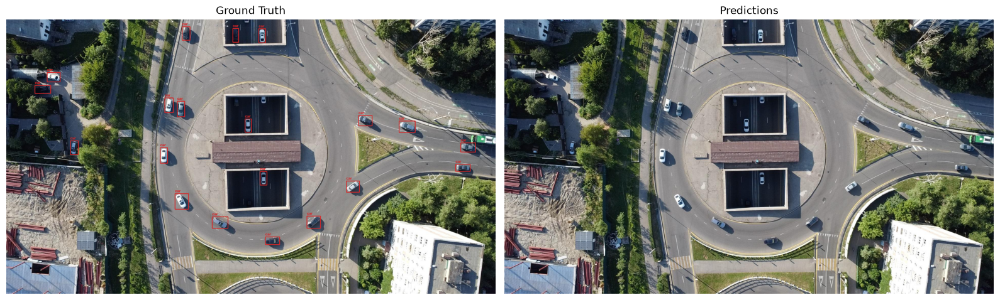

<Figure size 1200x800 with 0 Axes>

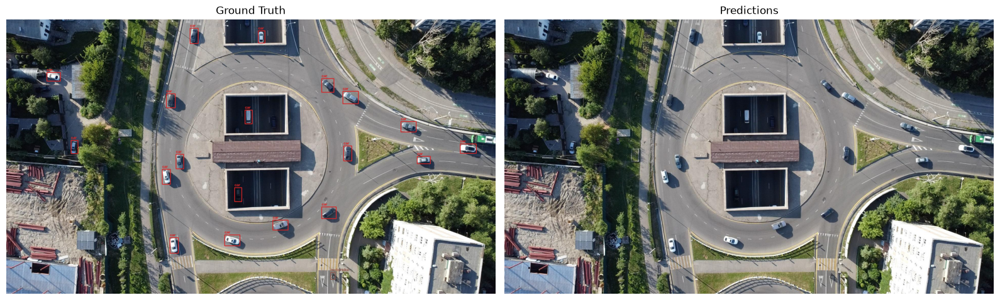

<Figure size 1200x800 with 0 Axes>

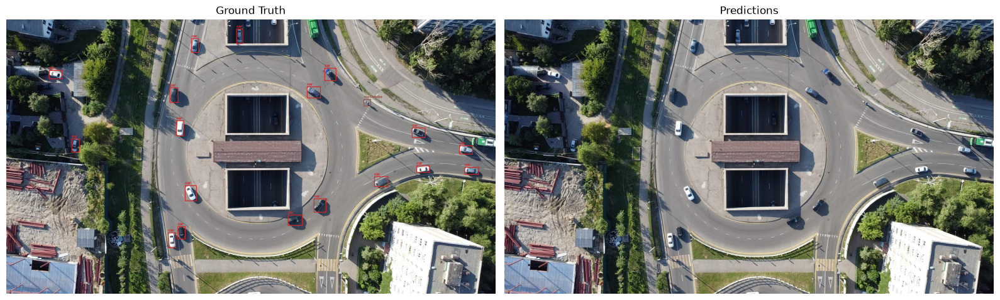

<Figure size 1200x800 with 0 Axes>


Evaluating: YOLO11m (COCO)



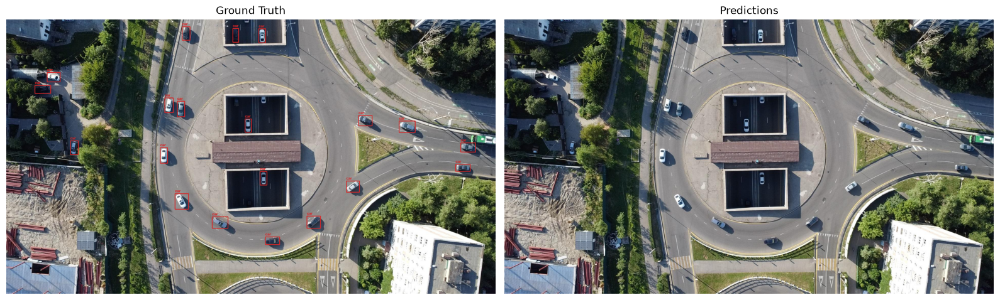

<Figure size 1200x800 with 0 Axes>

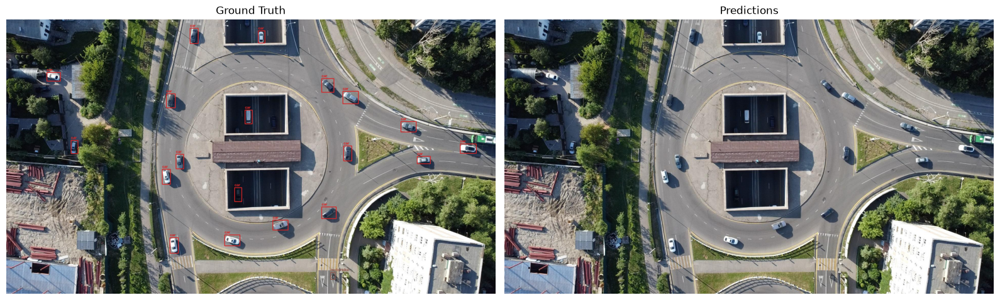

<Figure size 1200x800 with 0 Axes>

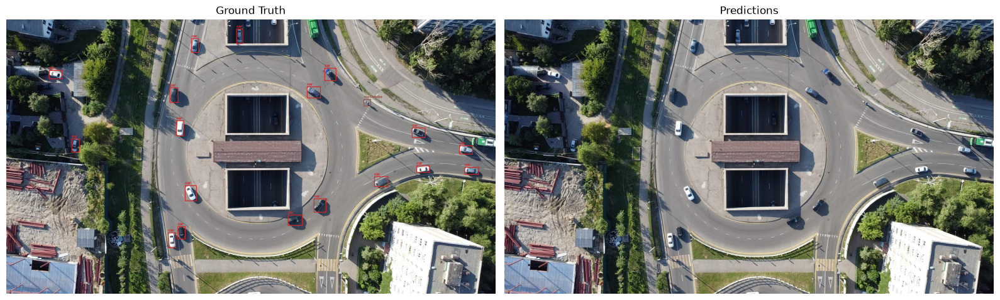

<Figure size 1200x800 with 0 Axes>


Evaluating: RT-DETR-l (COCO)



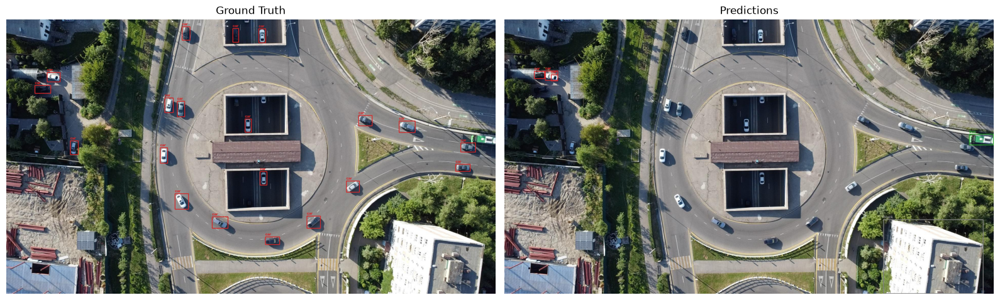

<Figure size 1200x800 with 0 Axes>

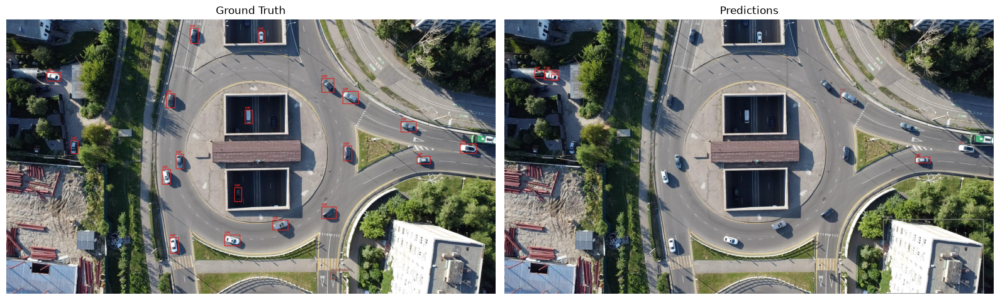

<Figure size 1200x800 with 0 Axes>

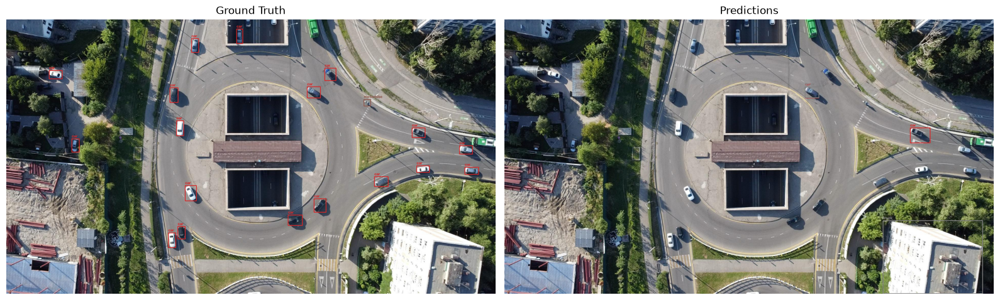

<Figure size 1200x800 with 0 Axes>

In [5]:
# Visualize predictions vs ground truth for each model
for model_name, model_path in MODELS.items():
    print(f"\n{'='*60}")
    print(f"Evaluating: {model_name}")
    print(f"{'='*60}\n")

    model = YOLO(model_path) if "yolo" in model_path.lower() else RTDETR(model_path)

    for img_path in images[:3]:
        img = cv2.imread(str(img_path))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        label_path = label_dir / (img_path.stem + ".txt")
        gt_boxes = load_yolo_labels(label_path, h, w)

        results = model(img_rgb, verbose=False)
        pred_boxes = []
        for r in results:
            for box in r.boxes:
                coco_id = int(box.cls[0])
                conf = float(box.conf[0])
                if conf < 0.25:
                    continue
                ds_name = coco_cls_to_dataset_name(coco_id)
                if ds_name is None:
                    continue
                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
                cls_idx = CLASS_NAMES.index(ds_name)
                pred_boxes.append({"class": cls_idx, "bbox": [x1, y1, x2, y2], "conf": conf})

        show_comparison(img_rgb, gt_boxes, pred_boxes, CLASS_NAMES)
        plt.suptitle(f"{model_name} - {img_path.name}", fontsize=14, y=0.98)
        plt.show()


In [6]:
# Compute per-class recall and precision
iou_threshold = 0.5
conf_threshold = 0.25

results_by_model = {}

for model_name, model_path in MODELS.items():
    print(f"Evaluating {model_name}...")
    model = YOLO(model_path) if "yolo" in model_path.lower() else RTDETR(model_path)

    tp = {name: 0 for name in CLASS_NAMES}
    fp = {name: 0 for name in CLASS_NAMES}
    fn = {name: 0 for name in CLASS_NAMES}

    for img_path in tqdm(images, desc=model_name):
        img = cv2.imread(str(img_path))
        h, w = img.shape[:2]

        label_path = label_dir / (img_path.stem + ".txt")
        gt_boxes = load_yolo_labels(label_path, h, w)

        results = model(img, verbose=False)
        pred_boxes = []
        for r in results:
            for box in r.boxes:
                coco_id = int(box.cls[0])
                conf = float(box.conf[0])
                if conf < conf_threshold:
                    continue
                ds_name = coco_cls_to_dataset_name(coco_id)
                if ds_name is None:
                    continue
                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
                cls_idx = CLASS_NAMES.index(ds_name)
                pred_boxes.append({"class": cls_idx, "bbox": [x1, y1, x2, y2]})

        matched_gt = set()
        for pred in pred_boxes:
            pred_cls_name = CLASS_NAMES[pred["class"]]
            best_gt_idx, best_iou = -1, 0.0
            for i, gt in enumerate(gt_boxes):
                if i in matched_gt:
                    continue
                iou = compute_iou(pred["bbox"], gt["bbox"])
                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = i

            if best_iou >= iou_threshold and pred["class"] == gt_boxes[best_gt_idx]["class"]:
                tp[pred_cls_name] += 1
                matched_gt.add(best_gt_idx)
            else:
                fp[pred_cls_name] += 1

        for i, gt in enumerate(gt_boxes):
            if i not in matched_gt:
                fn[CLASS_NAMES[gt["class"]]] += 1

    results_by_model[model_name] = {"tp": tp, "fp": fp, "fn": fn}


Evaluating YOLO11n (COCO)...


YOLO11n (COCO): 100%|██████████| 20/20 [00:00<00:00, 38.05it/s]


Evaluating YOLO11m (COCO)...


YOLO11m (COCO): 100%|██████████| 20/20 [00:01<00:00, 11.91it/s]


Evaluating RT-DETR-l (COCO)...


RT-DETR-l (COCO): 100%|██████████| 20/20 [00:07<00:00,  2.57it/s]


In [7]:
# Display per-class metrics
print("\n" + "="*80)
print("PER-CLASS PRECISION / RECALL / F1")
print("="*80 + "\n")

for model_name, metrics in results_by_model.items():
    print(f"\n{model_name}")
    print("-" * 80)
    print(f"{'Class':<20} {'Precision':<12} {'Recall':<12} {'F1':<12} {'Support':<10}")
    print("-" * 80)

    tp, fp, fn = metrics["tp"], metrics["fp"], metrics["fn"]

    for cls_name in CLASS_NAMES:
        precision = tp[cls_name] / (tp[cls_name] + fp[cls_name]) if (tp[cls_name] + fp[cls_name]) > 0 else 0
        recall = tp[cls_name] / (tp[cls_name] + fn[cls_name]) if (tp[cls_name] + fn[cls_name]) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        support = tp[cls_name] + fn[cls_name]
        print(f"{cls_name:<20} {precision:<12.3f} {recall:<12.3f} {f1:<12.3f} {support:<10}")

    total_tp = sum(tp.values())
    total_fp = sum(fp.values())
    total_fn = sum(fn.values())
    avg_precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0
    avg_recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0
    avg_f1 = 2 * avg_precision * avg_recall / (avg_precision + avg_recall) if (avg_precision + avg_recall) > 0 else 0
    print("-" * 80)
    print(f"{'OVERALL':<20} {avg_precision:<12.3f} {avg_recall:<12.3f} {avg_f1:<12.3f} {total_tp + total_fn:<10}")



PER-CLASS PRECISION / RECALL / F1


YOLO11n (COCO)
--------------------------------------------------------------------------------
Class                Precision    Recall       F1           Support   
--------------------------------------------------------------------------------
PMT                  0.000        0.000        0.000        0         
articulated-bus      0.000        0.000        0.000        0         
bus                  0.000        0.000        0.000        84        
car                  0.182        0.020        0.037        98        
freight              0.000        0.000        0.000        0         
motorbike            0.000        0.000        0.000        10        
small bus            0.000        0.000        0.000        38        
truck                0.000        0.000        0.000        26        
--------------------------------------------------------------------------------
OVERALL              0.182        0.008        0.015        256   

In [8]:
# Summary and recommendation
print("\n" + "="*80)
print("SUMMARY")
print("="*80 + "\n")

for model_name, metrics in results_by_model.items():
    tp, fp, fn = metrics["tp"], metrics["fp"], metrics["fn"]
    total_tp = sum(tp.values())
    total_fp = sum(fp.values())
    total_fn = sum(fn.values())
    avg_recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0

    print(f"{model_name}:")
    print(f"  Total detections: {total_tp + total_fp}")
    print(f"  True positives: {total_tp}")
    print(f"  False positives: {total_fp}")
    print(f"  False negatives: {total_fn}")
    print(f"  Average recall: {avg_recall:.3f}")
    print()

print("\nRECOMMENDATION:")
print("If average recall > 0.7 for your target classes, the pretrained model may be sufficient.")
print("If recall < 0.5 or you need better performance on specific classes, fine-tuning is recommended.")
print("Proceed to notebook 02 for SAM-assisted relabeling, then notebook 03 for training.")



SUMMARY

YOLO11n (COCO):
  Total detections: 11
  True positives: 2
  False positives: 9
  False negatives: 254
  Average recall: 0.008

YOLO11m (COCO):
  Total detections: 17
  True positives: 8
  False positives: 9
  False negatives: 248
  Average recall: 0.031

RT-DETR-l (COCO):
  Total detections: 362
  True positives: 31
  False positives: 331
  False negatives: 225
  Average recall: 0.121


RECOMMENDATION:
If average recall > 0.7 for your target classes, the pretrained model may be sufficient.
If recall < 0.5 or you need better performance on specific classes, fine-tuning is recommended.
Proceed to notebook 02 for SAM-assisted relabeling, then notebook 03 for training.
